## Node2Vec:

---

In [4]:
import pickle

with open('../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)

In [6]:
from node2vec import Node2Vec

node2vec = Node2Vec(
    G, 
    seed=42, 
    dimensions=64, 
    walk_length=30, 
    num_walks=200, 
    workers=4 # n_jobs
)

Computing transition probabilities:   0%|          | 0/150 [00:00<?, ?it/s]

In [7]:
model = node2vec.fit(
    window=10,
    min_count=1,
    batch_words=4
)

In [8]:
embeddings = model.wv
print(f"Successfully embedded {len(embeddings.key_to_index)} nodes into 64-dimensional space.")
print("150 nodes, each represented by 64 dimensional vector")

Successfully embedded 150 nodes into 64-dimensional space.
150 nodes, each represented by 64 dimensional vector


---

## PCA:

In [9]:
print(type(embeddings))

<class 'gensim.models.keyedvectors.KeyedVectors'>


In [10]:
import numpy as np

# Converting from strings to keys
node_id = list(model.wv.key_to_index.keys())

# Sorting
node_id.sort(key=int)
vectors_64d = np.array([model.wv[str(node)] for node in node_id])

In [11]:
print(f"Class type: {type(vectors_64d)}")
print(f"Shape: {vectors_64d.shape}")


Class type: <class 'numpy.ndarray'>
Shape: (150, 64)


In [12]:
display(vectors_64d)


array([[ 0.00792382, -0.10699474,  0.10572577, ..., -0.14189951,
        -0.2333011 , -0.00700098],
       [ 0.21536998, -0.20849921, -0.0669045 , ..., -0.17852423,
        -0.07912367, -0.26448214],
       [-0.0131096 , -0.10820079,  0.02708445, ..., -0.12184067,
        -0.09242258, -0.01100282],
       ...,
       [ 0.26297617, -0.00812328, -0.1886379 , ..., -0.12742704,
        -0.03346727, -0.2284929 ],
       [ 0.0268084 ,  0.09990192,  0.11386093, ..., -0.19176911,
        -0.08979379,  0.03802339],
       [ 0.28146258, -0.09839384, -0.07226271, ..., -0.22061887,
        -0.05816957, -0.22900657]], dtype=float32)

In [13]:
# Loading the pyshcological profile labels:

node_labels = np.load('../01-Dataset/node_labels.npy')
display(node_labels)

array([2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 1, 2,
       2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 2, 1, 0, 2, 2, 0,
       1, 0, 1, 1, 0, 2, 2, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 1, 0, 2, 1, 0,
       2, 0, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0,
       0, 2, 2, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 2, 0, 1,
       1, 1, 2, 0, 2, 1, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1], dtype=int64)

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

In [17]:
vectors_2d = pca.fit_transform(vectors_64d)
print(f"Shape: {vectors_2d.shape}")

Shape: (150, 2)


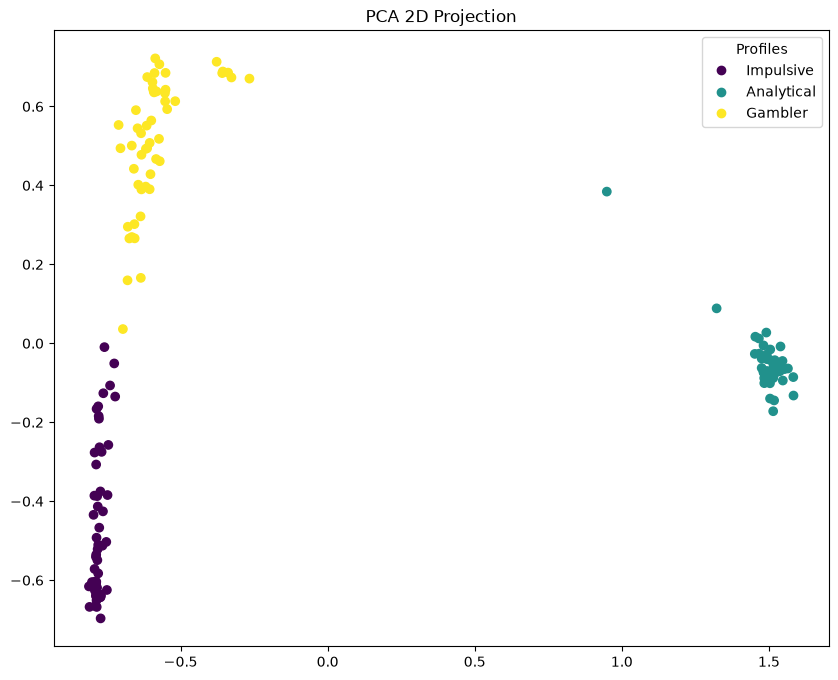

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

scatter = plt.scatter(x=vectors_2d[:, 0], y=vectors_2d[:, 1], c=node_labels)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')
plt.title('PCA 2D Projection')

plt.show()

---

### t-SNE:

In [6]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, 
            perplexity=30, 
            max_iter=1000, 
            random_state=42
        )